In [1]:
import earthaccess

/home/gray/miniforge3/envs/py6s-env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import pandas as pd
from datetime import datetime, timedelta, timezone


bbox = (-106.9816016190, 34.9927956264, -106.5500976652, 35.2464837223)
acq = datetime(2025, 1, 24, 18, 17, 52, tzinfo=timezone.utc)
temporal = ((acq - timedelta(days=1)).strftime("%Y-%m-%d"),
            (acq + timedelta(days=1)).strftime("%Y-%m-%d"))

granules = earthaccess.search_data(
    short_name="AERDB_L2_VIIRS_SNPP",
    bounding_box=bbox,
    temporal=temporal,
    count=200
)

rows = []
for g in granules:
    gd = g  # earthaccessのオブジェクト
    # dict化（earthaccessの版によっては to_dict が使える）
    if hasattr(g, "to_dict"):
        gd = g.to_dict()

    umm = gd.get("umm", {}) if isinstance(gd, dict) else {}
    te = umm.get("TemporalExtent", {}).get("RangeDateTime", {})
    start = te.get("BeginningDateTime")
    end   = te.get("EndingDateTime")

    title = None
    if isinstance(gd, dict):
        title = gd.get("title") or umm.get("GranuleUR") or umm.get("AdditionalAttributes", None)

    rows.append({"start_utc": start, "end_utc": end, "title": title})

df = pd.DataFrame(rows).sort_values(["start_utc"])
print(df.to_string(index=False))


               start_utc                  end_utc            title
2025-01-23T19:18:00.000Z 2025-01-23T19:24:00.000Z LAADS:8682526215
2025-01-23T19:24:00.000Z 2025-01-23T19:30:00.000Z LAADS:8682526426
2025-01-23T21:00:00.000Z 2025-01-23T21:06:00.000Z LAADS:8682811418
2025-01-24T19:00:00.000Z 2025-01-24T19:06:00.000Z LAADS:8683651406
2025-01-24T20:42:00.000Z 2025-01-24T20:48:00.000Z LAADS:8683753176
2025-01-25T20:24:00.000Z 2025-01-25T20:30:00.000Z LAADS:8684710277


In [4]:
def parse_z(s: str) -> datetime:
    return datetime.fromisoformat(s.replace("Z", "+00:00"))

acq = datetime(2025, 1, 24, 18, 17, 52, tzinfo=timezone.utc)

df2 = df.copy()
df2["start_dt"] = df2["start_utc"].apply(parse_z)
df2["delta_sec"] = (df2["start_dt"] - acq).abs().dt.total_seconds()

best_idx = df2["delta_sec"].idxmin()
print("Best row:\n", df2.loc[best_idx, ["title", "start_utc", "end_utc", "delta_sec"]])

best = granules[best_idx]
print("Best granule object:", best)


Best row:
 title                LAADS:8683651406
start_utc    2025-01-24T19:00:00.000Z
end_utc      2025-01-24T19:06:00.000Z
delta_sec                      2528.0
Name: 3, dtype: object
Best granule object: Collection: {'ShortName': 'AERDB_L2_VIIRS_SNPP', 'Version': '2'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -101.01725, 'Latitude': 17.011444}, {'Longitude': -72.253098, 'Latitude': 21.364805}, {'Longitude': -74.416252, 'Latitude': 42.284969}, {'Longitude': -109.754074, 'Latitude': 36.951756}, {'Longitude': -101.01725, 'Latitude': 17.011444}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2025-01-24T19:00:00.000Z', 'EndingDateTime': '2025-01-24T19:06:00.000Z'}}
Size(MB): 11.4479722976685
Data: ['https://data.laadsdaac.earthdatacloud.nasa.gov/prod-lads/AERDB_L2_VIIRS_SNPP/AERDB_L2_VIIRS_SNPP.A2025024.1900.002.2025025071427.nc']


In [5]:
'''

paths = earthaccess.download([best], local_path="../data/viirs_aerdb_l2", threads=4)
print(paths)
'''


'\n\npaths = earthaccess.download([best], local_path="../data/viirs_aerdb_l2", threads=4)\nprint(paths)\n'

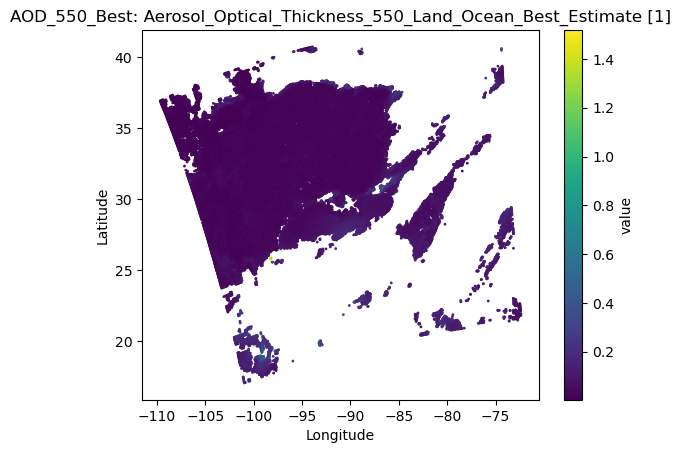

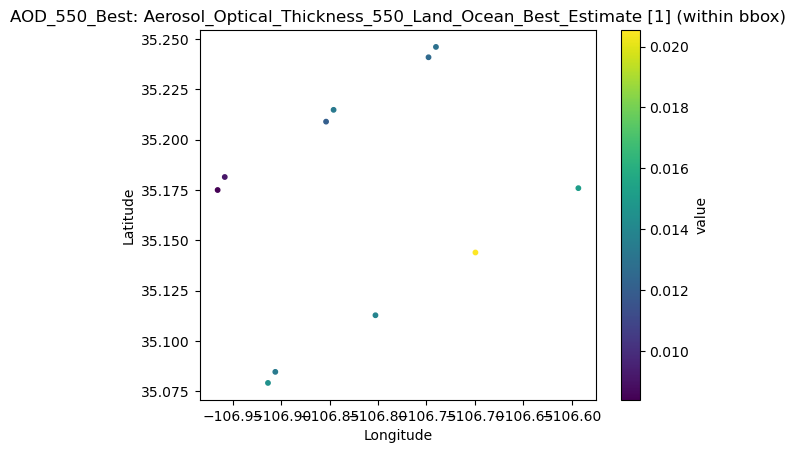

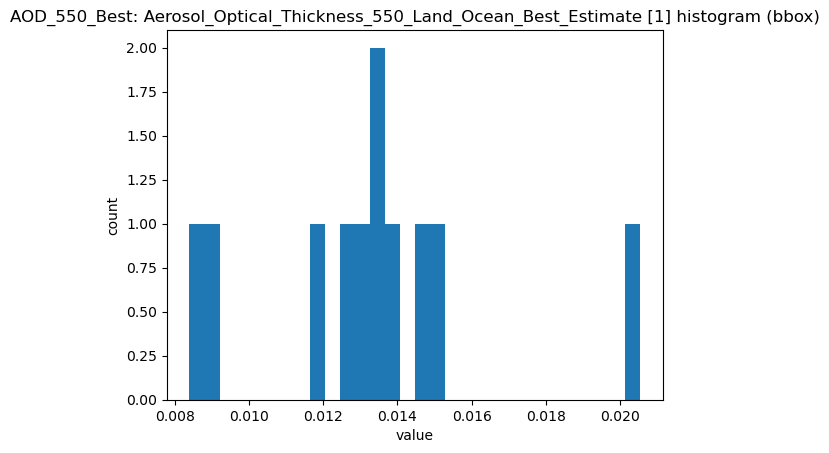

AOD_550_Best: Aerosol_Optical_Thickness_550_Land_Ocean_Best_Estimate [1] N = 11 min/median/mean/max = 0.008401220664381981 0.013329965062439442 0.013242660428990017 0.020539134740829468


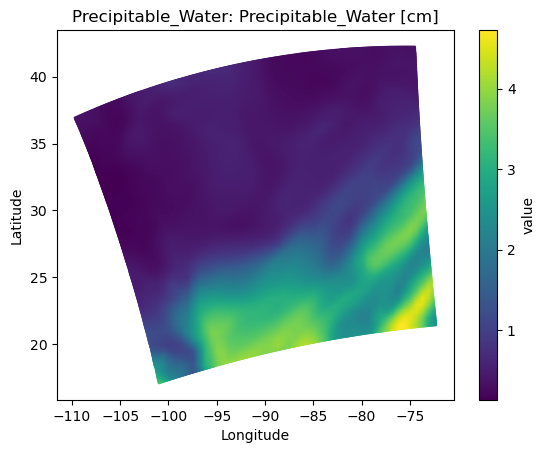

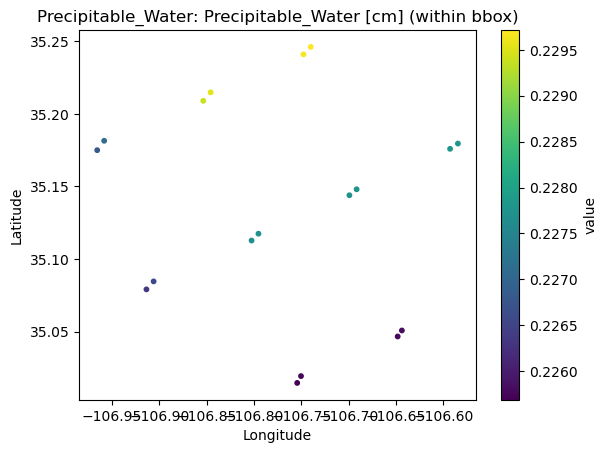

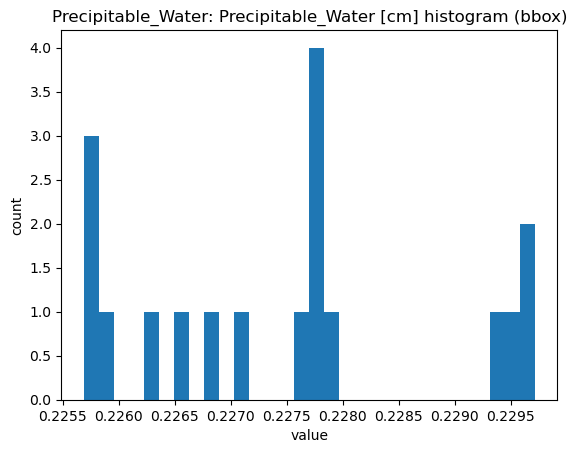

Precipitable_Water: Precipitable_Water [cm] N = 18 min/median/mean/max = 0.22568802535533905 0.2276974320411682 0.2274871360924509 0.22971530258655548


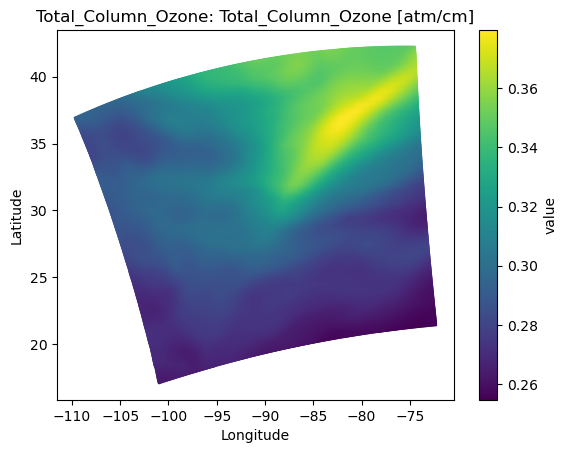

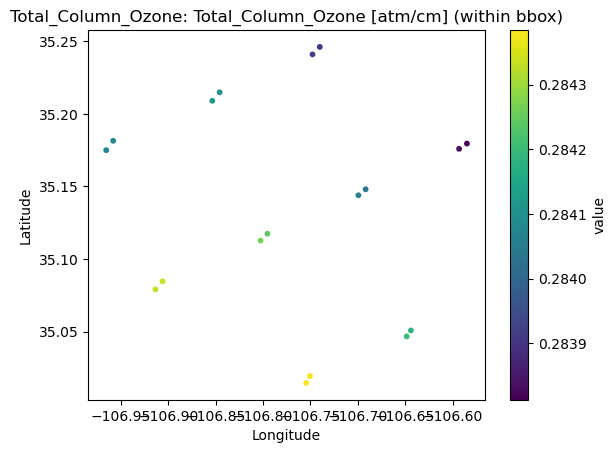

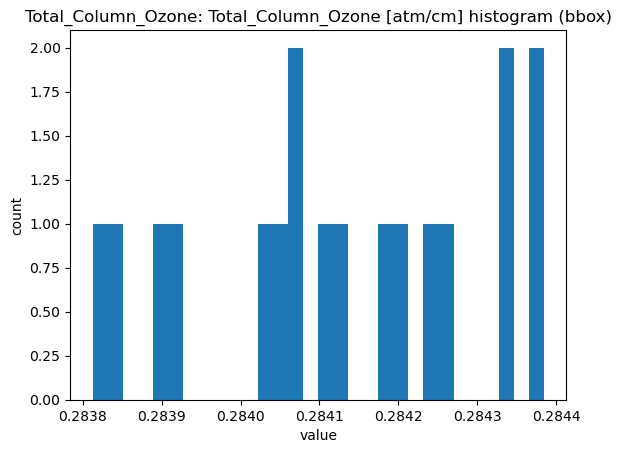

Total_Column_Ozone: Total_Column_Ozone [atm/cm] N = 18 min/median/mean/max = 0.2838127911090851 0.2841132879257202 0.2841241525279151 0.28438422083854675


In [13]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

fp = "../data/viirs_aerdb_l2/AERDB_L2_VIIRS_SNPP.A2025024.1900.002.2025025071427.nc"

# PlanetScope bbox (W, S, E, N)
bbox = (-106.9816016190, 34.9927956264, -106.5500976652, 35.2464837223)
W, S, E, N = bbox

ds = xr.open_dataset(fp, decode_timedelta=False)

lat = ds["Latitude"].values
lon = ds["Longitude"].values

vars_to_plot = {
    "AOD_550_Best": "Aerosol_Optical_Thickness_550_Land_Ocean_Best_Estimate",
    "Precipitable_Water": "Precipitable_Water",
    "Total_Column_Ozone": "Total_Column_Ozone",
}

def scatter_map(lon, lat, val, title, s=1):
    v = np.array(val, dtype=float).ravel()
    x = lon.ravel()
    y = lat.ravel()
    m = np.isfinite(v) & np.isfinite(x) & np.isfinite(y)
    plt.figure()
    plt.scatter(x[m], y[m], c=v[m], s=s)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(title)
    plt.colorbar(label="value")
    plt.show()

def scatter_bbox(lon, lat, val, title, s=6):
    v = np.array(val, dtype=float)
    m = (lon >= W) & (lon <= E) & (lat >= S) & (lat <= N) & np.isfinite(v)
    plt.figure()
    plt.scatter(lon[m], lat[m], c=v[m], s=s)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(title + " (within bbox)")
    plt.colorbar(label="value")
    plt.show()
    return v[m]

def hist(vals, title):
    vals = np.asarray(vals, dtype=float)
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        print(title, ": no valid values")
        return
    plt.figure()
    plt.hist(vals, bins=30)
    plt.title(title + " histogram (bbox)")
    plt.xlabel("value")
    plt.ylabel("count")
    plt.show()
    print(title, "N =", vals.size,
          "min/median/mean/max =",
          float(np.nanmin(vals)), float(np.nanmedian(vals)),
          float(np.nanmean(vals)), float(np.nanmax(vals)))

for label, varname in vars_to_plot.items():
    da = ds[varname]
    units = da.attrs.get("units", "")
    title = f"{label}: {varname} [{units}]"

    # 1) swath全体
    scatter_map(lon, lat, da.values, title, s=1)

    # 2) bbox内
    bbox_vals = scatter_bbox(lon, lat, da.values, title, s=10)

    # 3) bbox内ヒスト
    hist(bbox_vals, title)


In [ ]:
import os, json
import pandas as pd


# ---- input ----
fp = "../data/viirs_aerdb_l2/AERDB_L2_VIIRS_SNPP.A2025024.1900.002.2025025071427.nc"

# PlanetScope bbox (W, S, E, N)
bbox = (-106.9816016190, 34.9927956264, -106.5500976652, 35.2464837223)
W, S, E, N = bbox

# ---- output dir ----
out_dir = "../data"
os.makedirs(out_dir, exist_ok=True)

# ---- load ----
ds = xr.open_dataset(fp, decode_timedelta=False)

lat = ds["Latitude"].values
lon = ds["Longitude"].values

aod_name = "Aerosol_Optical_Thickness_550_Land_Ocean_Best_Estimate"
pw_name  = "Precipitable_Water"
o3_name  = "Total_Column_Ozone"

aod = ds[aod_name].values.astype(float)
pw  = ds[pw_name].values.astype(float)
o3  = ds[o3_name].values.astype(float)

# bbox mask + finite
m = (lon >= W) & (lon <= E) & (lat >= S) & (lat <= N)
m = m & np.isfinite(aod) & np.isfinite(pw) & np.isfinite(o3)

aod_v = aod[m]
pw_v  = pw[m]
o3_v  = o3[m]

def stats(x):
    x = np.asarray(x, dtype=float)
    return {
        "N": int(x.size),
        "min": float(np.nanmin(x)),
        "median": float(np.nanmedian(x)),
        "mean": float(np.nanmean(x)),
        "max": float(np.nanmax(x)),
    }

record = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "source_file": fp,
    "bbox_wsen": {"W": W, "S": S, "E": E, "N": N},
    "variables": {
        "AOD_550": {
            "varname": aod_name,
            "units": ds[aod_name].attrs.get("units", ""),
            **stats(aod_v),
        },
        "Precipitable_Water": {
            "varname": pw_name,
            "units": ds[pw_name].attrs.get("units", ""),
            **stats(pw_v),
        },
        "Total_Column_Ozone": {
            "varname": o3_name,
            "units": ds[o3_name].attrs.get("units", ""),
            **stats(o3_v),
        },
    },
}

# ---- save JSON ----
json_path = os.path.join(out_dir, "aerdb_representative_values.json")
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(record, f, ensure_ascii=False, indent=2)

# ---- save CSV (flat) ----
rows = []
for k, v in record["variables"].items():
    rows.append({
        "name": k,
        "varname": v["varname"],
        "units": v["units"],
        "N": v["N"],
        "min": v["min"],
        "median": v["median"],
        "mean": v["mean"],
        "max": v["max"],
    })
df = pd.DataFrame(rows)
csv_path = os.path.join(out_dir, "aerdb_representative_values.csv")
df.to_csv(csv_path, index=False)

print("Saved:")
print(" -", json_path)
print(" -", csv_path)
print(df.to_string(index=False))


Saved:
 - ../data/aerdb_representative_values.json
 - ../data/aerdb_representative_values.csv
              name                                                varname  units  N      min   median     mean      max
           AOD_550 Aerosol_Optical_Thickness_550_Land_Ocean_Best_Estimate      1 11 0.008401 0.013330 0.013243 0.020539
Precipitable_Water                                     Precipitable_Water     cm 11 0.226346 0.227736 0.228035 0.229715
Total_Column_Ozone                                     Total_Column_Ozone atm/cm 11 0.283833 0.284075 0.284091 0.284335
